# 05. HDR light fields

A single exposure clips the highlights and buries the shadows in noise, and refocusing makes this worse: it averages many rays, so one clipped highlight leaks into every refocused photo. HDR light fields capture more range by varying exposure, either across the views within one shot or by bracketing the whole light field over time. This notebook builds the classic HDR tool chain (response calibration, merging, tone mapping, exposure fusion) on a synthetic light field with a dynamic range of several thousand to one. It compares one-shot per-view bracketing with full temporal bracketing and a single-exposure baseline, and ends by showing why refocusing must happen on linear radiance.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs of textures).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import lf` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lf
from lf import hdr, refocus, LightField

rad_lf = hdr.synthetic_hdr_light_field(n_views=7, size=128)
gt_c = rad_lf.center_view
print(rad_lf, '| measured dynamic range:', round(rad_lf.meta['dynamic_range']))

LightField('synthetic_hdr', angular 7x7, spatial 128x128, 3 ch) | measured dynamic range: 5940


## The scene

The views hold linear radiance, not values in $[0, 1]$, so they must be tone mapped to be displayed. The grass is dark, the text is mid-grey and the gravel disc is very bright, and a single 8-bit photo cannot show all three well.

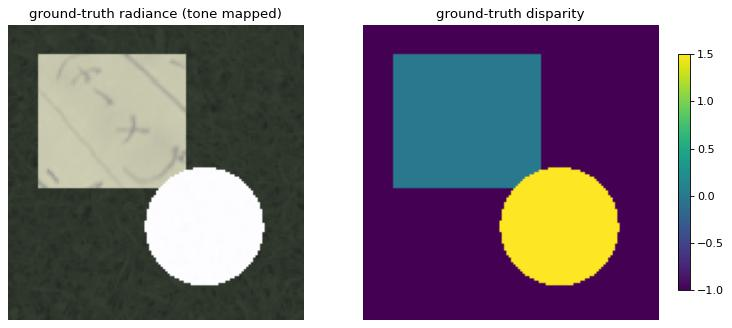

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].imshow(hdr.tonemap(gt_c)); axes[0].set_title('ground-truth radiance (tone mapped)'); axes[0].axis('off')
im = axes[1].imshow(rad_lf.meta['gt_disparity'], cmap='viridis')
axes[1].set_title('ground-truth disparity'); axes[1].axis('off')
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()

The ground truth needs a tone-mapping operator to be shown at all, which is the first hint that the display step is a separate stage from the measurement.

## Three exposures of the centre view

We capture the centre view at three exposures with the gamma camera model from `simulate_capture`. The exposures are $1/32$, $1$ and $32$, which is the range that covers this scene; the brief's $1/8$ to $8$ would miss the bright gravel and the dark grass.

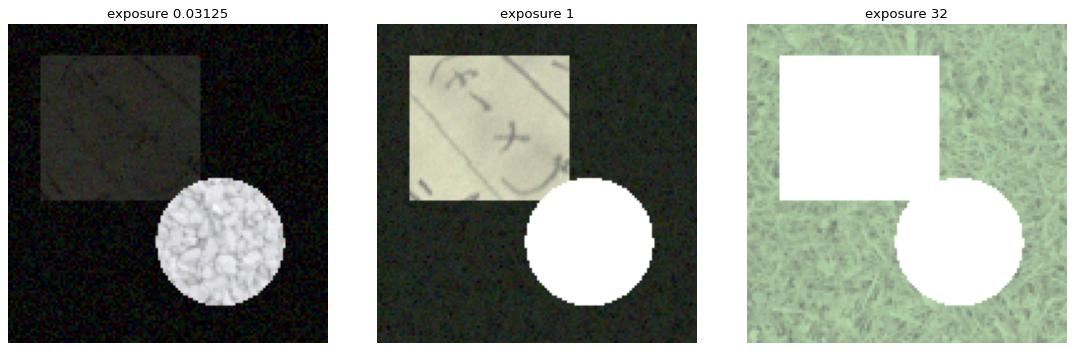

In [3]:
exposures = (1 / 32, 1.0, 32.0)
rng = np.random.default_rng(0)
ldr_c = [hdr.simulate_capture(gt_c, t, crf='gamma', rng=rng) for t in exposures]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, t, img in zip(axes, exposures, ldr_c):
    ax.imshow(img); ax.set_title(f'exposure {t:g}'); ax.axis('off')
plt.tight_layout()

The $1/32$ shot keeps the gravel detail, but the grass is almost black and noisy. The $32$ shot shows the grass well, but the gravel and the text are clipped to white. No single shot holds the whole range.

## Recovering the camera response

`solve_response` estimates the log inverse response $g$ by least squares, from pixels seen at several exposures. The scale of $g$ is fixed at the mid-grey level, so we compare the shape with the gamma-2.2 law that the simulator used.

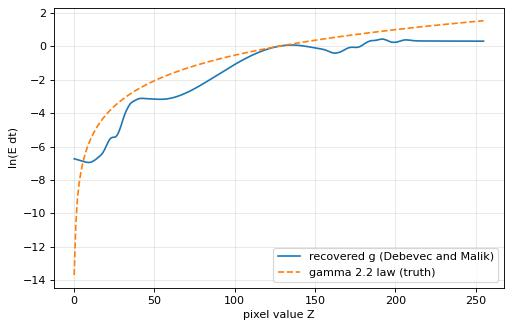

In [4]:
samples = hdr.sample_pixels(ldr_c, n=200, rng=np.random.default_rng(0))
g, ln_e = hdr.solve_response(samples, exposures)
z = np.arange(256) / 255.0
g_true = 2.2 * (np.log(np.maximum(z, 1e-3)) - np.log(128 / 255.0))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(np.arange(256), g, label='recovered g (Debevec and Malik)')
ax.plot(np.arange(256), g_true, '--', label='gamma 2.2 law (truth)')
ax.set_xlabel('pixel value Z'); ax.set_ylabel('ln(E dt)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

The recovered curve follows the gamma law in the mid-range where the three exposures overlap. At the ends, the curve is dominated by noise near black and by clipping near white, so the hat weights should down-weight those levels.

## Merging and tone mapping

`merge_hdr` combines the three exposures into a radiance image, using the hat weights to trust mid-range values. `tonemap` then makes it displayable. `exposure_fusion` is the Mertens alternative: it blends the display images directly, without a response curve.

estimate                       log-RMSE   PSNR tone-mapped
single exposure 1.0               1.303              25.15
merged (3 exposures)              0.249              30.01


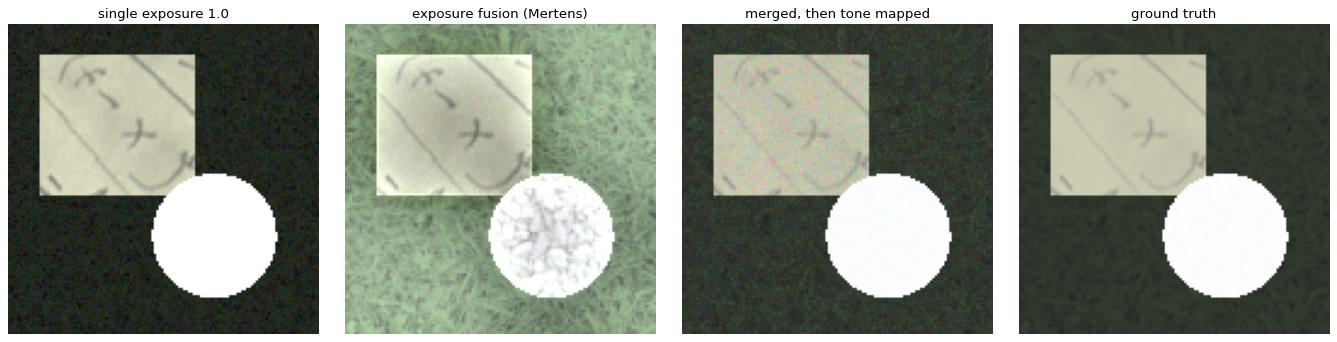

In [5]:
inv = hdr.inverse_crf('gamma')
rad_merge = hdr.merge_hdr(ldr_c, exposures, response='gamma')
fused = hdr.exposure_fusion(ldr_c)
print(f"{'estimate':28s} {'log-RMSE':>10s} {'PSNR tone-mapped':>18s}")
print(f"{'single exposure 1.0':28s} {hdr.log_rmse(inv(ldr_c[1]), gt_c):10.3f} {hdr.psnr_tonemapped(inv(ldr_c[1]), gt_c):18.2f}")
print(f"{'merged (3 exposures)':28s} {hdr.log_rmse(rad_merge, gt_c):10.3f} {hdr.psnr_tonemapped(rad_merge, gt_c):18.2f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
panels = [('single exposure 1.0', ldr_c[1]), ('exposure fusion (Mertens)', fused),
          ('merged, then tone mapped', hdr.tonemap(rad_merge)), ('ground truth', hdr.tonemap(gt_c))]
for ax, (title, img) in zip(axes, panels):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title); ax.axis('off')
plt.tight_layout()

The merged radiance keeps the gravel and the grass at once, and it is much closer to the ground truth than any single exposure. Exposure fusion gives a pleasing display image without radiance, but it cannot be refocused linearly, so the rest of the notebook uses radiance.

## Strategy A: one exposure per view

Strategy A captures every view at its own exposure in one shot. We use a checkerboard exposure pattern, so each view sees all three exposures among its neighbours. `merge_bracketed_views` warps every view onto the target using the disparity map, merges them and rejects the ones that disagree.

In [6]:
em = hdr.exposure_pattern(rad_lf.nu, rad_lf.nv, kind='checker')
print('exposure per view (rows = u, columns = v):')
print(em)
ldr_A, em = hdr.capture_bracketed_views(rad_lf, em, rng=np.random.default_rng(0))
hdr_A = hdr.merge_bracketed_views(ldr_A, em, disparity=rad_lf.meta['gt_disparity'])
per_view = hdr.evaluate_hdr_lf(hdr_A, rad_lf)
hdr_A_nodepth = hdr.merge_bracketed_views(ldr_A, em, disparity=None)
print('Strategy A, with ground-truth disparity: mean log-RMSE', round(per_view['mean'], 3),
      '| centre', round(per_view['center'], 3))
print('Strategy A, no depth (no warping)       : mean log-RMSE',
      round(hdr.evaluate_hdr_lf(hdr_A_nodepth, rad_lf)['mean'], 3))

exposure per view (rows = u, columns = v):
[[3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02]
 [1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00]
 [3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01]
 [3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02]
 [1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00]
 [3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01]
 [3.125e-02 3.200e+01 1.000e+00 3.125e-02 3.200e+01 1.000e+00 3.125e-02]]


Strategy A, with ground-truth disparity: mean log-RMSE 0.487 | centre 0.3
Strategy A, no depth (no warping)       : mean log-RMSE 1.036


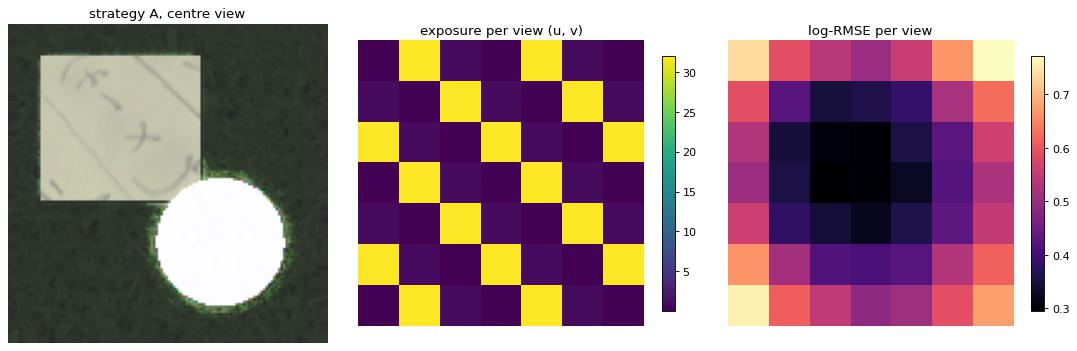

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
axes[0].imshow(hdr.tonemap(hdr_A.center_view)); axes[0].set_title('strategy A, centre view'); axes[0].axis('off')
im1 = axes[1].imshow(em, cmap='viridis'); axes[1].set_title('exposure per view (u, v)'); axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], shrink=0.8)
im2 = axes[2].imshow(per_view['per_view'], cmap='magma'); axes[2].set_title('log-RMSE per view'); axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], shrink=0.8)
plt.tight_layout()

One shot recovers the scene with a mean log-RMSE of 0.49 (0.30 at the centre view). Dropping the depth map raises the error to 1.04, so the depth-based warp is what makes one-shot capture work.

## Strategy C: temporal bracketing

Strategy C captures the whole light field at all three exposures, three shots in total, and merges each view independently. It needs no depth, so it is an upper bound for strategy A.

In [8]:
C = hdr.temporal_bracket_hdr_lf(rad_lf, exposures)
one_lf = LightField(inv(hdr.capture_bracketed_views(rad_lf, np.full((7, 7), 1.0),
                                                   rng=np.random.default_rng(0))[0].views), 'one_exposure')
rows = [('1 shot, one exposure (1.0)', 1, hdr.evaluate_hdr_lf(one_lf, rad_lf)),
        ('strategy A (1 shot, per view)', 1, per_view),
        ('strategy C (3 shots, temporal)', C['shots'], hdr.evaluate_hdr_lf(C['hdr_lf'], rad_lf))]
print(f"{'method':32s} {'shots':>5s} {'mean log-RMSE':>14s} {'centre log-RMSE':>16s}")
for name, shots, res in rows:
    print(f"{name:32s} {shots:5d} {res['mean']:14.3f} {res['center']:16.3f}")

method                           shots  mean log-RMSE  centre log-RMSE
1 shot, one exposure (1.0)           1          1.304            1.291
strategy A (1 shot, per view)        1          0.487            0.300
strategy C (3 shots, temporal)       3          0.248            0.249


Strategy C is the most accurate, as expected, but it takes three times the shots. Strategy A has about twice its error (0.49 against 0.25) in one shot, and it is far better than a single exposure (1.30).

## Refocusing: LDR versus radiance

The last step is refocusing. `ldr_refocus_comparison` refocuses at $\alpha = 1.5$ (the gravel) in three orders: average the display values of a single exposure, average linear values and tone map last, or tone map each view and then refocus. `hdr_refocus` is the correct order, shear and average linear radiance and tone map at the end.

refocus order                             log-RMSE (radiance)  PSNR (display)
LDR: average display values                             1.148           23.24
LDR: linearise, then average                            1.101           27.98
tone map each view, then refocus                            -           22.45
radiance refocus (strategy A HDR)                       0.687               -


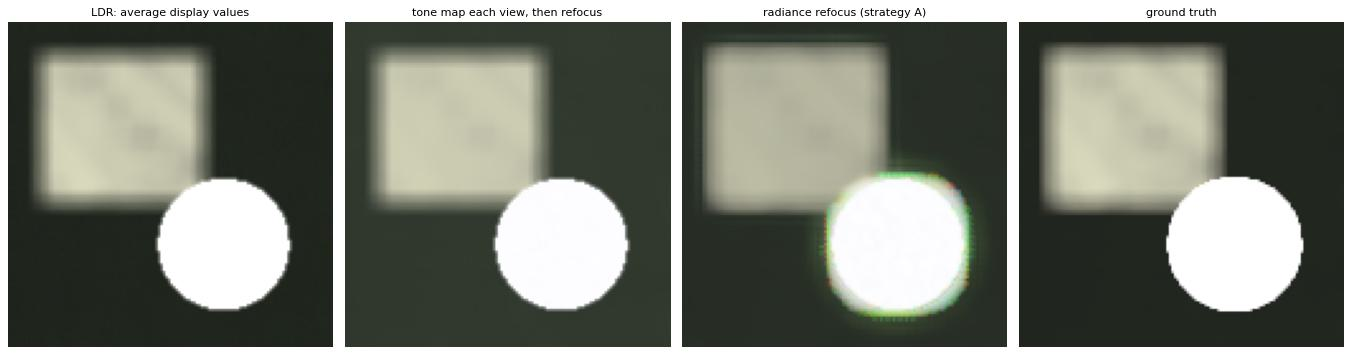

In [9]:
alpha_f = 1.5
cmp = hdr.ldr_refocus_comparison(rad_lf, alpha_f, exposure=1.0)
hdr_A_img, hdr_A_rad = hdr.hdr_refocus(hdr_A, alpha_f, return_radiance=True)
print(f"{'refocus order':40s} {'log-RMSE (radiance)':>20s} {'PSNR (display)':>15s}")
print(f"{'LDR: average display values':40s} {cmp['log_rmse_ldr']:20.3f} {cmp['psnr_display_ldr']:15.2f}")
print(f"{'LDR: linearise, then average':40s} {cmp['log_rmse_ldr_lin']:20.3f} {cmp['psnr_display_ldr_lin']:15.2f}")
print(f"{'tone map each view, then refocus':40s} {'-':>20s} {cmp['psnr_display_tm_first']:15.2f}")
print(f"{'radiance refocus (strategy A HDR)':40s} {hdr.log_rmse(hdr_A_rad, refocus.refocus(rad_lf, alpha_f)):20.3f} {'-':>15s}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
panels = [('LDR: average display values', cmp['ldr']), ('tone map each view, then refocus', cmp['tm_first']),
          ('radiance refocus (strategy A)', hdr_A_img), ('ground truth', cmp['gt_display'])]
for ax, (title, img) in zip(axes, panels):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title, fontsize=10); ax.axis('off')
plt.tight_layout()

Averaging clipped display values is the least accurate (log-RMSE 1.15), and linearising first helps only a little (1.10), because clipping has already destroyed the gravel. Refocusing the radiance and tone mapping last (third panel) keeps the bright gravel, which the display-first orders clip, and that is why the rule is to average linear values and display last. The coloured fringes at the gravel edge in the third panel are residual error from the one-shot merge.

## Depth-free refocusing

When no depth map is available, `merge_bracketed_refocused` merges in the refocused domain: it shears each exposure group by $\alpha$ and merges the groups as an exposure stack. It is exact only on the plane $\alpha$ itself, so the error here is higher than strategy A with depth.

In [10]:
print(f"{'alpha':>6s} {'depth-free':>12s} {'with depth':>12s}   (log-RMSE vs ground-truth refocus)")
for a in (-1.0, 0.0, 1.5):
    ref_gt = refocus.refocus(rad_lf, a)
    ref_free = hdr.merge_bracketed_refocused(ldr_A, em, alpha=a)
    ref_depth = hdr.hdr_refocus(hdr_A, a, return_radiance=True)[1]
    print(f"{a:6.1f} {hdr.log_rmse(ref_free, ref_gt):12.3f} {hdr.log_rmse(ref_depth, ref_gt):12.3f}")

 alpha   depth-free   with depth   (log-RMSE vs ground-truth refocus)
  -1.0        1.057        0.108


   0.0        0.786        0.193
   1.5        0.367        0.687


The depth-free merge is exact only on the plane it is sheared to. At $\alpha = 1.5$ (the gravel) it beats the depth-based merge here, but at $\alpha = -1$ and $0$ its error is much larger, while the depth-based merge stays accurate everywhere. Depth-free merging is a shortcut for one plane, not a general refocus.

## Where to go next

Read [docs/09_hdr_light_field.md](../docs/09_hdr_light_field.md) for the derivations, the four strategies, the aperture-area bracketing that this notebook leaves out, and the table of results. The matching tab in the Streamlit explorer (`streamlit run app/streamlit_app.py`) lets you change the exposure pattern and the scene gain.